In [1]:
import ast
import os
import optuna
import ipynbname
import pandas as pd
import numpy as np
from optuna.exceptions import TrialPruned
from Functions.AutoCloud_V4_4 import *
from Functions.Utils import *
from Functions.Graphs import *
from Functions.TedaGraphs import *
from Functions.Utils_OPT_R2 import *
import copy

FileName = ipynbname.name()

# Configuração do experimento
FEEDBACK = 'symmetric'      # 'symmetric' (gradiente no passo atual) ou 'random' (ablação: RFLO + DFA)
WTAG, WTAP = False, False   # configuração principal: soma ponderada dos grânulos (eq. 36)
EOL = 0.3                   # limiar de fim de vida (EoL) do HI

# rho dinâmico (AutoCloud_V4_2): começa em 0 e é ajustado a cada iteração maximizando V = média(cov)*média(sp)
RHO_TARGET = 'RUL'           # 'HI' (causal, HI um passo à frente) ou 'RUL' (oráculo: usa a RUL real; n_rho previsões por passo)
RHO_MIN, RHO_MAX, N_RHO = 1e-3, 1, 4   # grade log-espaçada de candidatos
LAM = 1.0                   # fator de esquecimento (1.0 = todos os passos com o mesmo peso)

def RunTag(feedback=None, wtaG=None, wtaP=None):
    # Uma pasta de resultados por configuração (feedback, wtaG, wtaP)
    feedback = FEEDBACK if feedback is None else feedback
    wtaG = WTAG if wtaG is None else wtaG
    wtaP = WTAP if wtaP is None else wtaP
    return f'{FileName}_{feedback}_G{int(wtaG)}P{int(wtaP)}'

def RefEoL(sig, eol, nI, mO, mode):
    '''
    Referência da RUL real baseada no limiar de EoL (eq. 12): RUL_real = iEoL - k_dado.
    O AutoCloud calcula rulR = ref - k, com k = j + 2 na iteração j, e o PrepareData
    alinha a iteração j à amostra k_dado = k0 + j. Logo ref = iEoL - k0 + 2.
    Retorna ref e J, o número de iterações com RUL real >= 1.
    '''
    sig = np.asarray(sig, dtype=float)
    if not np.any(sig <= eol): raise ValueError('O HI nunca atinge o limiar de EoL.')
    iEoL = int(np.argmax(sig <= eol))
    k0 = (max(nI, 1, mO) if mode in ('ahead', 1) else max(nI, 1)) - 1
    return iEoL - k0 + 2, iEoL - k0

def nOMax(sig, eol):
    '''
    Maior nO (modo 'ahead') para o qual o fluxo do PrepareData alcança a última amostra antes do EoL.
    A última janela fica em k = K - nO - 2 (o PrepareData descarta a última); exigir k >= iEoL - 1
    dá nO <= K - iEoL - 1, independente de nI e mO. No modo 'past' o fluxo sempre alcança o EoL.
    '''
    sig = np.asarray(sig, dtype=float)
    return len(sig) - int(np.argmax(sig <= eol)) - 1

out_path = os.path.join('Optimization', RunTag(), 'multi', 'Optimization.csv')
dfs = [pd.read_csv(out_path)] if os.path.exists(out_path) else []
RS = pd.read_excel(r'Dataset\RS.xlsx')
HI = pd.read_excel(r'Dataset\HI.xlsx')
sig = HI['PC1'].values

c:\Users\Usuario\Desktop\Python\Batteries_Prognostics\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


HI (HI_Granularity): cov=0.849 | sp=0.915 | V=média(cov*sp)=0.8103


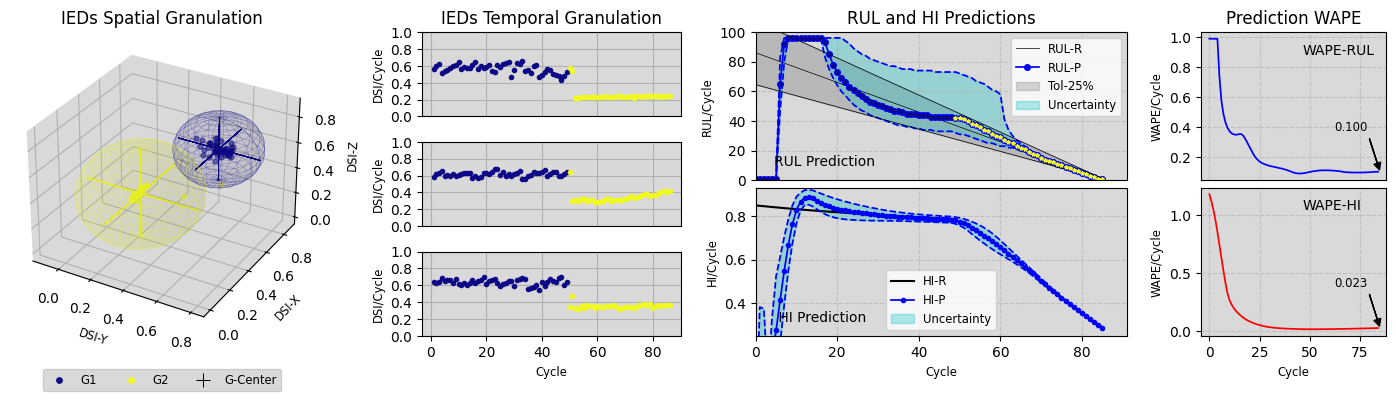

In [2]:
params = [3.5,28,[70],8,0,1,2,5,19,1,0]
m,nI,nR,nO,mO,N1,N2,N3,τ,mode,act = params
X, Y, Z = PrepareData(RS, HI, nI, nO, mO, 1, mode)
ref, J = RefEoL(sig, EOL, nI, mO, mode)
if len(X) < J: print(f'Aviso: nO={nO} > {nOMax(sig, EOL)}: o fluxo termina antes do EoL (última RUL real = {J-len(X)+1}).')
nI = len(Y[0])
if isinstance(nR, str): nR = ast.literal_eval(nR)

# RUL intervalar (RULInterv2): protocolo 3 na janela de entrada + análise intervalar da rede (pesos numéricos)
RHO = 0.5                   # rho inicial: múltiplo do erro estimado do HI (eP) somado/subtraído aos valores previstos
# rho dinâmico (sugestão 3): subida de gradiente online em V = média(cov*sp) do HI
RHO_DYN = True              # False: rho estático (= RHO)
RHO_ETA, RHO_T, RHO_BETA = 0.1, 0.5, 0.0   # passo, temperatura da cobertura suavizada (escore |e|/e_est), momento
RHO_MIN, RHO_MAX = 1e-9, 5
INTR_STATE = 'reset'        # estado recorrente intervalar: 'reset' (só a incerteza da janela do passo) ou 'carry' (propagado)

teda=AutoCloud(m=m,nI=nI,nR=nR,nO=nO+mO,ηS=[N1,N2,N3],mode=mode,act=act,
               tau=τ,eol=EOL,ref=ref,wtaG=WTAG,wtaP=WTAP,feedback=FEEDBACK,mO=mO,
               rho=RHO,lam=LAM,intr_state=INTR_STATE,
               rho_dyn=RHO_DYN,rho_eta=RHO_ETA,rho_T=RHO_T,rho_beta=RHO_BETA,rho_min=RHO_MIN,rho_max=RHO_MAX)

for j,_ in enumerate(X[:J]):

    teda.run(X[j])
    teda.RUL_Prediction(Y[j],mode='interval',lim=len(sig)-nI+1,show=False)
    teda.WAPE_HI2(Y[j],Z[j])
    teda.Adapt(Y[j],Z[j])
    teda.UpdateRLS(mode='HI')

print(f"HI (HI_Granularity): cov={teda.cov:.3f} | sp={teda.sp:.3f} | V=média(cov*sp)={teda.V:.4f}")
PlotDSI_3D_PLT(teda,xi=0, yf=100)


In [3]:
PlotDSI_3D_PLY(teda,xi=0, yf=100)


In [12]:
PlotSeriesPLY(ySeries=[teda.eR, teda.eP],names=['E_real','E_pred'])
# rho dinâmico: valor usado em cada passo e gradiente de v_k(rho)
PlotSeriesPLY(ySeries=[teda.rho_used], names=['rho'], title='rho por iteração')
PlotSeriesPLY(ySeries=[teda.rho_grad_hist], names=['gradiente'], title='gradiente de v_k(rho) por iteração')

In [6]:
params = [3.5,28,[70],8,0,1,2,5,19,1,0]
m,nI,nR,nO,mO,N1,N2,N3,τ,mode,act = params
X, Y, Z = PrepareData(RS, HI, nI, nO, mO, 1, mode)
ref, J = RefEoL(sig, EOL, nI, mO, mode)
if len(X) < J: print(f'Aviso: nO={nO} > {nOMax(sig, EOL)}: o fluxo termina antes do EoL (última RUL real = {J-len(X)+1}).')
nI = len(Y[0])
if isinstance(nR, str): nR = ast.literal_eval(nR)

INTR_STATE = 'reset'        

cov, sp = np.array([]),np.array([])
rhos = np.linspace(1e-2,2,35)

for rho in rhos:
    teda=AutoCloud(m=m,nI=nI,nR=nR,nO=nO+mO,ηS=[N1,N2,N3],mode=mode,act=act,
                tau=τ,eol=EOL,ref=ref,wtaG=WTAG,wtaP=WTAP,feedback=FEEDBACK,mO=mO,
                rho=rho,lam=LAM,intr_state=INTR_STATE,rho_dyn=False)   # varredura de rho estático (referência)

    for j,_ in enumerate(X[:J]):

        teda.run(X[j])
        teda.RUL_Prediction(Y[j],mode='interval',lim=len(sig)-nI+1,show=False)
        teda.WAPE_HI2(Y[j],Z[j])
        teda.Adapt(Y[j],Z[j])
        teda.UpdateRLS(mode='HI')

    cov = np.append(cov,teda.cov)
    sp = np.append(sp,teda.sp)


In [7]:
PlotSeriesPLY(xSeries=[rhos, rhos],ySeries=[cov, sp])
PlotSeriesPLY(xSeries=[rhos],ySeries=[cov* sp])


In [ ]:
PlotSeriesPLY(xSeries=[rhos, rhos],ySeries=[cov, sp])
PlotSeriesPLY(xSeries=[rhos],ySeries=[cov* sp])
